In [1]:
from keras.preprocessing import image
# Image is a submodule in preprocessing module, which works like csv to show images

from keras.preprocessing.image import ImageDataGenerator

In [2]:
img = image.load_img(r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\cat.webp', target_size = (250, 250))

# Note: cv2 returns a numpy array whereas image does not. So we cannot perform numpy operations on it

type(image)

module

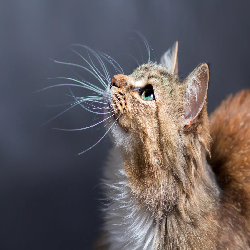

In [3]:
img

In [4]:
# Creating ImageDataGenerator object

datagen = ImageDataGenerator(
    rotation_range = 30,
    shear_range = 0.2,
    horizontal_flip = True,
    vertical_flip = False,
    zoom_range = 0.2,
    width_shift_range = 0.2,
    height_shift_range = 0.2
)

# Vertical_flip = False bcz it will make the image of cat up-side down(legs up and other body down) and cats are not like that.

In [5]:
# Converting image to an array

img_2 = image.img_to_array(img)

img_2

array([[[ 90.,  98., 118.],
        [ 90.,  98., 116.],
        [ 90.,  98., 116.],
        ...,
        [ 58.,  63.,  75.],
        [ 58.,  63.,  75.],
        [ 58.,  63.,  75.]],

       [[ 90.,  98., 116.],
        [ 90.,  98., 116.],
        [ 90.,  98., 116.],
        ...,
        [ 58.,  63.,  75.],
        [ 58.,  63.,  75.],
        [ 58.,  63.,  75.]],

       [[ 90.,  99., 114.],
        [ 90.,  98., 116.],
        [ 90.,  98., 116.],
        ...,
        [ 58.,  63.,  75.],
        [ 58.,  63.,  75.],
        [ 58.,  63.,  75.]],

       ...,

       [[ 32.,  35.,  45.],
        [ 32.,  35.,  45.],
        [ 33.,  36.,  44.],
        ...,
        [166., 133., 117.],
        [168., 139., 121.],
        [119.,  95.,  78.]],

       [[ 32.,  35.,  45.],
        [ 32.,  35.,  45.],
        [ 33.,  36.,  46.],
        ...,
        [168., 134., 116.],
        [179., 148., 129.],
        [166., 138., 129.]],

       [[ 31.,  33.,  44.],
        [ 31.,  34.,  42.],
        [ 32.,  

In [6]:
img_2.shape

(250, 250, 3)

In [7]:
type(img_2)

numpy.ndarray

In [8]:
img_2.ndim

3

In [9]:
# ImageDataGenerator takes images in batch, so we will have to convert this image shape in 4D
# If a image is in 4D, means it is a batch
# For ex, size of image is (1,256,256,3) Means it is a 4d tensor of 1 image of size (256,256) with 3 channels

# If size of image is (10,256,256,3) Means it is a 4D tensor of 10 images of size (256,256) with 3 channels


image_batch = img_2.reshape(1,250,250,3)

# As img_2 is now a numpy array, we can perform 'rashape'(numpy's method) to it

In [10]:
image_batch.shape

(1, 250, 250, 3)

In [11]:
image_batch.ndim

# 4-Dimension

4

In [12]:
type(image_batch)

numpy.ndarray

# Performing Augmentation

In [13]:
i = 0

for new_images in datagen.flow(image_batch, batch_size = 1, save_to_dir = 'Augmented_images'):

    i += 1

    if i == 10:
        break

# Flow is a method of ImageDataGenerator's class and datagen is its object we created above.
# When we are dealing with one single image i.e a numpy array, we use 'flow()'
# There is one other method flow_from_directory() which we use when we have images in folder  (Will learn after this)

# batch_size = 1, means we want 1 more batch
# save_to_dir = 'Augmented_images' means will store this new_images in this folder
# Moreover flow() method goes onn generating images, so we need to give it a breaking condition

FileNotFoundError: [Errno 2] No such file or directory: 'Augmented_images\\_0_4637.png'

In [14]:
# We are getting this error msg bcz we don't have any folder named 'Augmented_images'
# So we will have to create it.

i = 0

for new_images in datagen.flow(image_batch, batch_size = 1, save_to_dir = '50 Day 50 - Augmented_Images'):

    i += 1

    if i == 10:
        break

# Go to this folder, we will have 10 newly generatedimages

# Training Model with 1000 images of cats and dogs to see accuracy.
# After this we will traing with Data Augmentation.

In [15]:
import cv2
import os
import pandas as pd
import numpy as np
import random

In [16]:
my_dir = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\50 Day 50 - Cats and Dogs images for Data Augmentation/Train'

In [17]:
categories = ['Dogs', 'Cats']

In [18]:
data = []

for i in categories:
    folder_path = os.path.join(my_dir, i)

    if i == 'cat':
        label = 0
    else:
        label = 1

    for j in os.listdir(folder_path):
        img_path = os.path.join(folder_path, j)
        img = cv2.imread(img_path)
        img = cv2.resize(img, (150,150))
        data.append([img, label])

In [19]:
data[0]

# data will contain numpy arrays of images and its corresponding labels

[array([[[127, 116, 118],
         [119, 105, 107],
         [125, 110, 112],
         ...,
         [150, 138, 136],
         [147, 135, 133],
         [141, 133, 133]],
 
        [[131, 119, 121],
         [122, 108, 110],
         [126, 112, 114],
         ...,
         [153, 141, 139],
         [149, 137, 135],
         [144, 136, 136]],
 
        [[133, 122, 124],
         [125, 111, 113],
         [129, 114, 116],
         ...,
         [156, 144, 142],
         [150, 138, 136],
         [146, 139, 137]],
 
        ...,
 
        [[ 87,  85,  76],
         [ 83,  80,  72],
         [ 78,  75,  66],
         ...,
         [ 84,  79,  70],
         [ 73,  68,  59],
         [ 75,  73,  63]],
 
        [[ 82,  78,  73],
         [ 82,  79,  71],
         [ 79,  77,  67],
         ...,
         [ 71,  66,  57],
         [ 83,  78,  69],
         [ 89,  87,  77]],
 
        [[ 76,  72,  67],
         [ 79,  76,  68],
         [ 73,  71,  61],
         ...,
         [ 99,  94,  85],
  

In [20]:
# Shuffling the data

random.shuffle(data)

In [21]:
data[0][1]

1

In [22]:
for i in data:
    print(i[1])
    break

1


In [23]:
# Putting images i.e numpy arrays in x and labels in y


x = []    # Contains arrays
y = []    # Contains labels
for i in data:
    x.append(i[0])
    y.append(i[1])
    

In [24]:
x[0]

array([[[ 42,  50,  67],
        [ 41,  51,  66],
        [ 52,  64,  74],
        ...,
        [ 68,  70,  70],
        [ 67,  69,  69],
        [ 67,  69,  69]],

       [[ 55,  64,  81],
        [ 58,  71,  85],
        [ 60,  74,  85],
        ...,
        [ 69,  71,  71],
        [ 68,  70,  70],
        [ 68,  70,  70]],

       [[ 44,  56,  73],
        [ 36,  52,  65],
        [ 38,  54,  66],
        ...,
        [ 66,  68,  68],
        [ 65,  67,  67],
        [ 65,  67,  67]],

       ...,

       [[ 54,  36,  25],
        [ 48,  33,  24],
        [ 38,  26,  21],
        ...,
        [171, 200, 214],
        [174, 203, 217],
        [173, 202, 216]],

       [[ 61,  43,  32],
        [ 56,  41,  32],
        [ 37,  25,  20],
        ...,
        [178, 207, 221],
        [176, 205, 218],
        [167, 196, 210]],

       [[ 55,  37,  26],
        [ 42,  27,  17],
        [ 32,  20,  14],
        ...,
        [184, 213, 227],
        [164, 193, 207],
        [171, 200, 214]]

In [25]:
y[0]

1

In [26]:
# Converting x and y to an array bcz model accepts only array, not a list

x = np.array(x)
y = np.array(y)

In [27]:
print(x.shape)
print(y.shape)

(2000, 150, 150, 3)
(2000,)


In [28]:
type(x)

numpy.ndarray

# 1) Model without `Data Augmentation`

In [29]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Conv2D, Flatten, Dense, MaxPooling2D

In [39]:
model_1 = Sequential()

model_1.add(Conv2D(32, kernel_size = (3,3), activation = 'relu', input_shape = (150,150,3)))
model_1.add(MaxPooling2D(pool_size = (2,2)))

model_1.add(Conv2D(32, kernel_size = (3,3), activation = 'relu'))
model_1.add(MaxPooling2D(pool_size = (2,2)))

model_1.add(Conv2D(64, kernel_size = (3,3), activation = 'relu'))
model_1.add(MaxPooling2D(pool_size = (2,2)))

model_1.add(Flatten())    # Converts 3d featur maps yo 1D feature vectors
# Dense Layers

model_1.add(Dense(64, activation = 'relu'))
model_1.add(Dropout(0.5))

model_1.add(Dense(1, activation = 'sigmoid'))

In [40]:
model_1.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 148, 148, 32)      896       
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 74, 74, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 72, 72, 32)        9248      
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 36, 36, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 34, 34, 64)        18496     
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 17, 17, 64)       

In [41]:
model_1.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [42]:
history_1 = model_1.fit(x, y, epochs = 3, validation_split = 0.1)

Epoch 1/3
57/57 [==============================] - 37s 597ms/step - loss: 0.1543 - accuracy: 0.9906 - val_loss: 0.0000e+00 - val_accuracy: 1.0000
Epoch 2/3
57/57 [==============================] - 34s 592ms/step - loss: 0.0000e+00 - accuracy: 1.0000 - val_loss: 0.0000e+00 - val_accuracy: 1.0000
Epoch 3/3
57/57 [==============================] - 32s 558ms/step - loss: 0.0000e+00 - accuracy: 1.0000 - val_loss: 0.0000e+00 - val_accuracy: 1.0000


array([[[[ 0.05533241,  0.00529936,  0.02352938,  0.08284727,
           0.02343509,  0.00828505,  0.01092263,  0.04034904,
           0.06016692, -0.1127468 , -0.0388544 , -0.09474492,
          -0.00975658,  0.11406195,  0.13892451,  0.02733278,
           0.11026313,  0.12663561, -0.08681919,  0.07037655,
          -0.07816728,  0.125543  , -0.08735532,  0.0983185 ,
           0.12321068,  0.00475037, -0.02461416,  0.091772  ,
          -0.05881626, -0.01223782, -0.06459471,  0.00811241],
         [ 0.00543373,  0.12009303,  0.11185877,  0.01346217,
           0.03995128, -0.11932375,  0.00317415, -0.09270531,
          -0.08772505, -0.01893616, -0.06023367,  0.1151232 ,
           0.03226864,  0.11334223,  0.03405497, -0.00995399,
           0.03935421,  0.01264701,  0.04086598, -0.12185745,
           0.02218073, -0.110047  , -0.04537854, -0.14341167,
           0.01312048, -0.05506144,  0.13799009, -0.01489801,
           0.09789952,  0.11107621, -0.12533197,  0.04270245],
      

# 2) `Using Data Augmentation`

When we have data organized like in one folder we have images of cats and in other folder we have images of dogs with train, test and validation images, seperate in 3 different folders. We use below method to generate images

Test-->1) Cats 2) Dogs <br>
Train-->1) Cats 2) Dogs <br>
Validation--> 1) Cats 2) Dogs

In [46]:
from keras.preprocessing.image import ImageDataGenerator

In [52]:
# Creating InageDataGenerator object for test and train both

train_datagen = ImageDataGenerator(
    rescale = 1./255,
    shear_range = 0.2,
    rotation_range = 30,
    horizontal_flip = True,
    zoom_range = 0.2
)

test_datagen = ImageDataGenerator(
    rescale = 1./255
)

In [53]:
# flow_from_directory is used when we have data arranges in our folders

train_generator = train_datagen.flow_from_directory(
    directory = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\50 Day 50 - Cats and Dogs images for Data Augmentation/Train',
    target_size = (150,150),
    batch_size = 16,
    class_mode = 'binary'
)


validation_generator = test_datagen.flow_from_directory(
    directory = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\50 Day 50 - Cats and Dogs images for Data Augmentation/Validation',
    target_size = (150,150),
    batch_size = 16,
    class_mode = 'binary'
)

Found 2000 images belonging to 2 classes.
Found 400 images belonging to 2 classes.


In [54]:
# Using same model

In [58]:
# We use fit_generator when we use ImageDataGenerator
# Insted of x and y, we pass train_generator

# Moreover, remember, while training, the new_augmented images will be used and not the original images

history_2 = model_1.fit_generator(train_generator,
                                  epochs = 3,
                                  validation_data = validation_generator)

C:\Users\jugal\AppData\Local\Temp\ipykernel_26660\2757962485.py:6: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history_2 = model_1.fit_generator(train_generator,


Epoch 1/3
125/125 [==============================] - 54s 429ms/step - loss: 0.6932 - accuracy: 0.5000
Epoch 2/3
125/125 [==============================] - 53s 422ms/step - loss: 0.6936 - accuracy: 0.5000
Epoch 3/3
125/125 [==============================] - 53s 425ms/step - loss: 0.6937 - accuracy: 0.5095


# Don't notice losses and accuracies here. This sessions is only for learning How to use `Data Augmentation`.

# Next Session: 51 - Pretrained models